# PRG Toolbox Tutorial: Momentum-Space Coarse Graining

This notebook shows how to use the **momentum-space** version of the PRG, introduced alongside the real-space one by [Meshulam et al. (2019)](https://doi.org/10.1103/PhysRevLett.123.178103) and studied in detail by [Nicoletti et al. (2020)](https://journals.aps.org/prresearch/abstract/10.1103/PhysRevResearch.2.023144).

Instead of merging pairs of correlated variables, here we remove the *fine-grained modes* of the population activity. We compute the principal components of the covariance matrix, keep only the $K$ with the largest eigenvalues, and rebuild each variable from them:

$$\phi_i^{(K)} = z_i \sum_{j=1}^{N} \sum_{\mu=1}^{K} u_{i\mu}\, u_{j\mu}\, (x_j - \langle x_j \rangle) \quad ,$$

where $u_\mu$ are the eigenvectors ordered by decreasing eigenvalue and $z_i$ rescales each variable to unit variance. At step $k$ we keep $K = N/2^k$ modes. We then ask the same question as in real space: as we coarse grain, does the distribution of $\phi$ become Gaussian, or does it approach a non-Gaussian form?

---

### First, let's load some data

As in *but_what_does_PRG_do.ipynb*, we use simulations of the multi-area model from Schmidt et al. (2018) [3], binarized in 5 ms bins.

In [1]:
import prg_toolbox as prg
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis

# Download spiking data (only the first time) and return the path to the file
file_path = prg.datasets.get_spike_data(files=['5E'])

# Load the spike timestamps and keep a random sample of 1024 neurons
data_format = 'tabular'
data_timestamps = prg.tools._load_timestamps(file_path, format=data_format)
timestamps = prg.tools._pick_random_sample_from_timestamps(data_timestamps, sample_size=1024)
del data_timestamps  # free memory, the full file is no longer needed

binary_array = prg.tools.binarize_data(timestamps, data_format=data_format, binsize_ms=5)
print(f'{binary_array.shape[0]} neurons, {binary_array.shape[1]} time bins')

✔ Ready: /home/shimoura/Github/prg_toolbox/example_notebooks/example_data_directory/spikes-V4-5E.gdf


1024 neurons, 10100 time bins


### Next, we run the momentum-space coarse graining

`MSVariables` plays the role that `CGVariables` plays in real space. There is one difference to keep in mind: the number of variables does not shrink, every step still has one variable per neuron. To save memory, the variables of a step are computed only when we ask for them, with `get_MS_variables(k)`.

The input does not need to be binary: continuous signals can be passed directly.

In [2]:
rg_steps = 8
MS_variables = prg.MSVariables(binary_array, rg_steps=rg_steps)

print('Modes kept at each step (K):', MS_variables.cutoffs)
print('Attributes:', list(MS_variables.__dict__.keys()))

Modes kept at each step (K): [1024  512  256  128   64   32   16    8    4]
Attributes: ['verbose', 'rg_steps', 'time_window', 'original_idx', 'cutoffs', 'eigenvalues', 'eigenvectors', '_centered_data']


#### Which modes are we keeping? The dashed lines mark the cutoffs $K = N/2^k$ on the covariance spectrum: at each step, everything to the right of the line is removed.

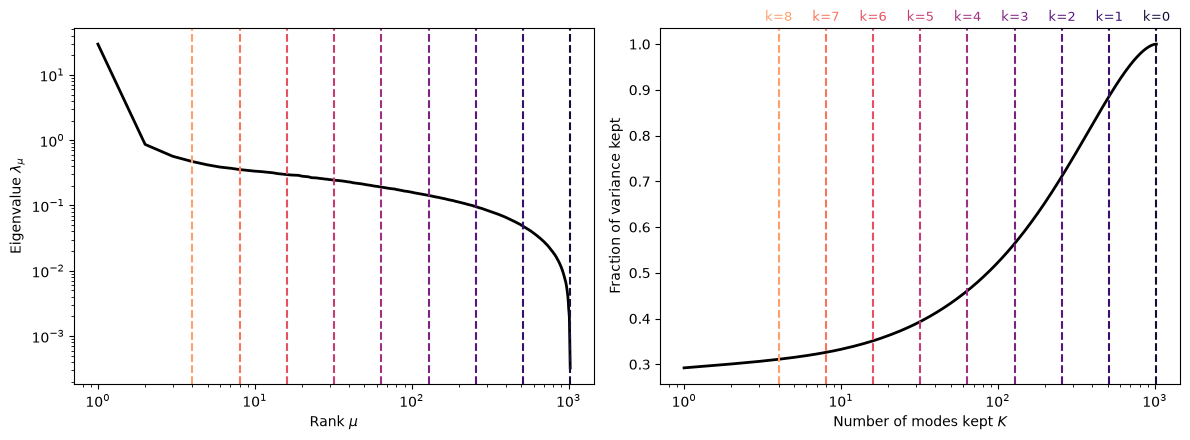

In [3]:
eigenvalues = MS_variables.eigenvalues
rank = np.arange(1, len(eigenvalues) + 1)
variance_kept = np.cumsum(eigenvalues) / np.sum(eigenvalues)
step_colors = plt.get_cmap('magma')(np.linspace(0.1, 0.8, rg_steps + 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].loglog(rank, eigenvalues, color='k', lw=2)
axes[0].set_xlabel('Rank $\\mu$')
axes[0].set_ylabel('Eigenvalue $\\lambda_\\mu$')

axes[1].semilogx(rank, variance_kept, color='k', lw=2)
axes[1].set_xlabel('Number of modes kept $K$')
axes[1].set_ylabel('Fraction of variance kept')

for k, K in enumerate(MS_variables.cutoffs):
    for ax in axes:
        ax.axvline(K, color=step_colors[k], ls='--', lw=1.5)
    axes[1].annotate(f'k={k}', (K, 1.02), color=step_colors[k], ha='center', fontsize=9,
                     xycoords=('data', 'axes fraction'))
plt.tight_layout()
plt.show()

#### And what happens to a single neuron? As modes are removed, its spike train turns into a smooth signal that follows the collective events of the population:

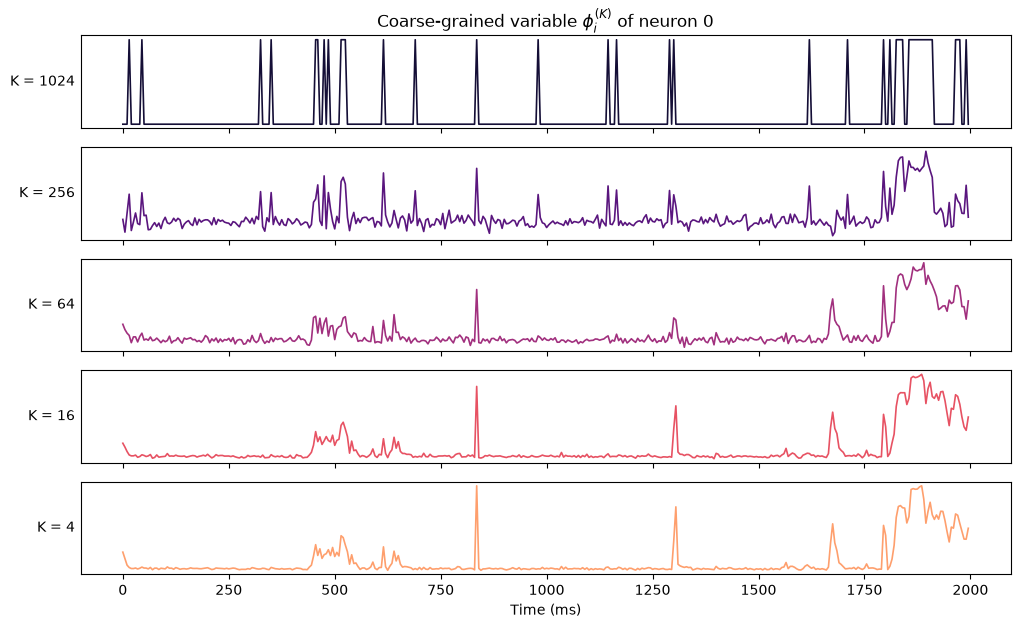

In [4]:
neuron = 0
time_ms = np.arange(400) * 5  # first 2 s, 5 ms bins
steps_to_show = [0, 2, 4, 6, 8]

fig, axes = plt.subplots(len(steps_to_show), 1, figsize=(12, 7), sharex=True)
for ax, k in zip(axes, steps_to_show):
    phi = MS_variables.get_MS_variables(k)[neuron, :len(time_ms)]
    ax.plot(time_ms, phi, color=step_colors[k], lw=1.2)
    ax.set_ylabel(f'K = {MS_variables.cutoffs[k]}', rotation=0, ha='right', va='center')
    ax.set_yticks([])
axes[-1].set_xlabel('Time (ms)')
axes[0].set_title(f'Coarse-grained variable $\\phi_i^{{(K)}}$ of neuron {neuron}')
plt.show()

### Now we can look at the distribution of the coarse-grained variables

`momentum_space_distribution` pools the values of all variables at each step. The same bins are used at every step (by default, 200 bins over $[-10, 10]$). Spiking data has long positive tails, so here we use a wider range. If values fall outside the bins, the toolbox warns you.

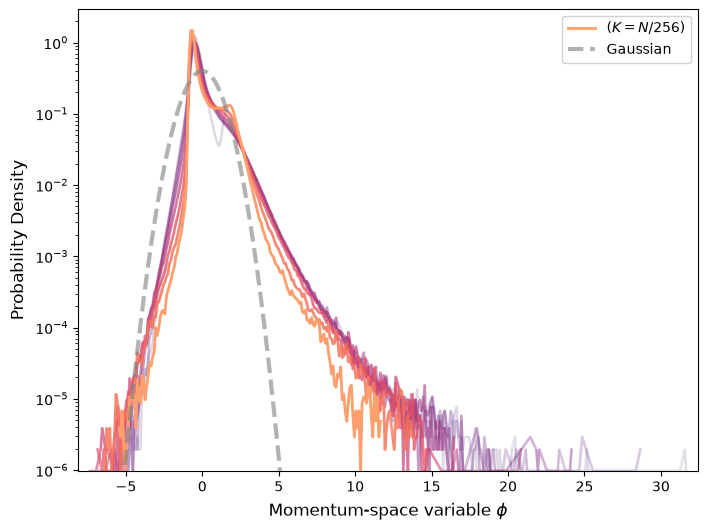

In [5]:
bins = np.linspace(-10, 45, 551)
MS_distribution = prg.momentum_space_distribution(MS_variables, bins=bins)

fig = plt.figure(figsize=(8, 6))
prg.plot.plot_momentum_space_distribution(MS_distribution)
plt.show()

#### The curves go from many modes (lighter) to only $K = N/256 = 4$ modes (opaque). Since every $\phi_i$ has zero mean and unit variance, the Gaussian reference (dashed) is exactly the standard normal, with nothing to fit.

### Validating results with surrogate data

As with the other observables, we compare with shuffled data (`shuffle_isi`), which keeps each neuron's activity but breaks the correlations between neurons. For independent variables, the coarse-grained variables should approach the Gaussian.

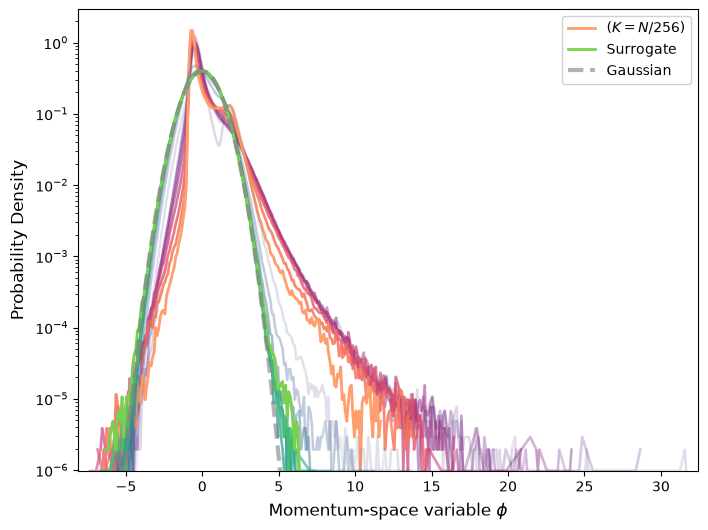

In [6]:
surrogate_array = prg.tools.shuffle_isi(binary_array, data_format='timeseries', random_seed=1)
MS_surrogate = prg.MSVariables(surrogate_array, rg_steps=rg_steps)
MS_surrogate_distribution = prg.momentum_space_distribution(MS_surrogate, bins=bins)

fig = plt.figure(figsize=(8, 6))
prg.plot.plot_momentum_space_distribution(MS_distribution, surrogate_data=MS_surrogate_distribution)
plt.show()

#### A simple way to quantify this is the excess kurtosis of $\phi$, which is zero for a Gaussian:

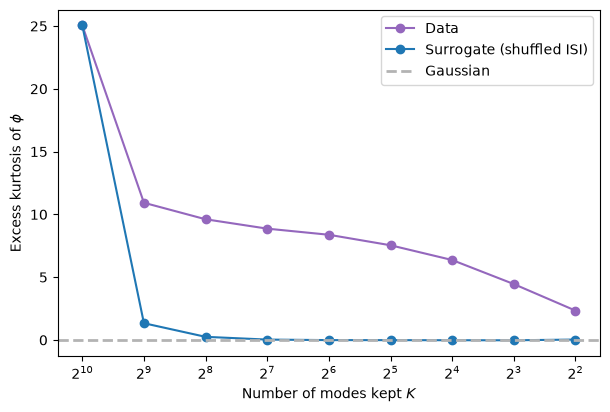

In [7]:
def excess_kurtosis_by_step(ms_variables):
    return [kurtosis(ms_variables.get_MS_variables(k).ravel()) for k in range(ms_variables.rg_steps + 1)]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(MS_variables.cutoffs, excess_kurtosis_by_step(MS_variables), 'o-', color='tab:purple', label='Data')
ax.plot(MS_surrogate.cutoffs, excess_kurtosis_by_step(MS_surrogate), 'o-', color='tab:blue', label='Surrogate (shuffled ISI)')
ax.axhline(0, color='0.7', ls='--', lw=2, label='Gaussian')
ax.set_xscale('log', base=2)
ax.invert_xaxis()
ax.set_xlabel('Number of modes kept $K$')
ax.set_ylabel('Excess kurtosis of $\\phi$')
ax.legend()
plt.show()

The surrogate reaches the Gaussian after a few steps, while the data stays clearly non-Gaussian. Note, however, that the kurtosis of the data keeps decreasing instead of settling: for a non-trivial fixed point we would want the curves to stop changing. Here, a single mode carries about 30% of the variance, and the last steps mostly isolate it.

### Real space and momentum space side by side

#### Both look at the same question: real space sums clusters of $2^k$ neurons, momentum space keeps the $N/2^k$ largest modes.

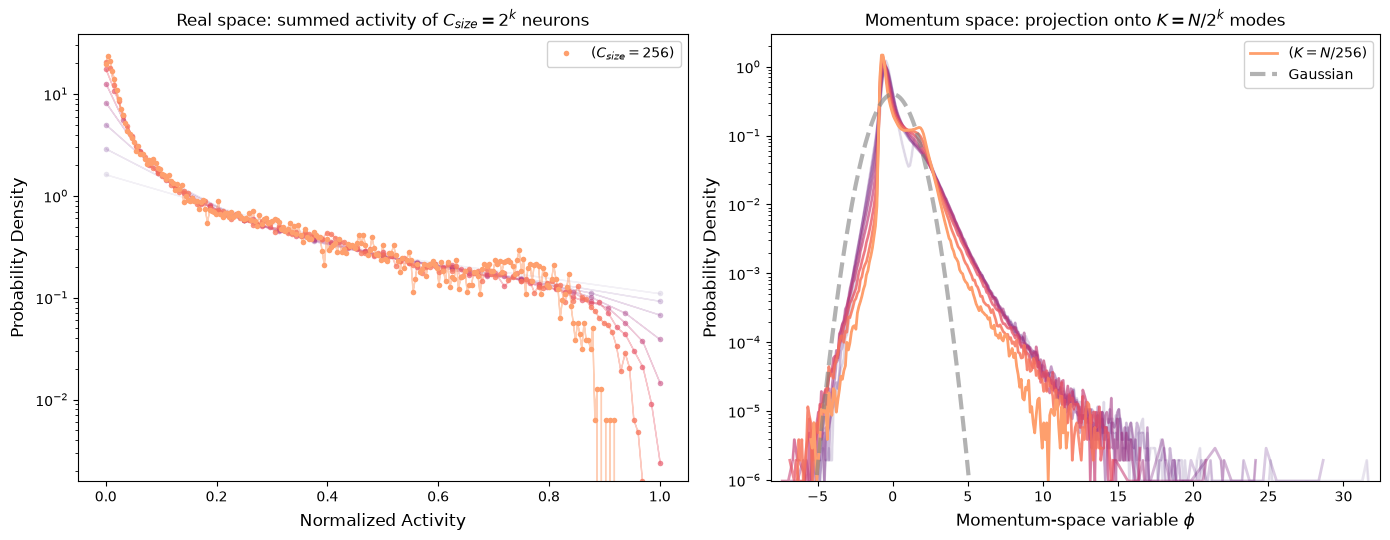

In [8]:
CG_variables = prg.CGVariables(binary_array, cluster_method='pearson', rg_steps=rg_steps)
activity = prg.activity_distribution(CG_variables)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
prg.plot.plot_activity_distribution(activity, ax=axes[0])
axes[0].set_title('Real space: summed activity of $C_{size} = 2^k$ neurons')
prg.plot.plot_momentum_space_distribution(MS_distribution, ax=axes[1])
axes[1].set_title('Momentum space: projection onto $K = N/2^k$ modes')
plt.tight_layout()
plt.show()

### A sanity check with a known answer

A good way to trust the method is to try it where we know the result. In the model of Appendix B of Nicoletti et al. (2020), at each time step every unit fires independently with the same probability $\xi$, drawn at random between 0 and 1. Its excess kurtosis can be computed exactly at every step (gray line below, with $r = K/N$), and with a single mode kept the distribution must be flat between $\pm\sqrt{3}$.

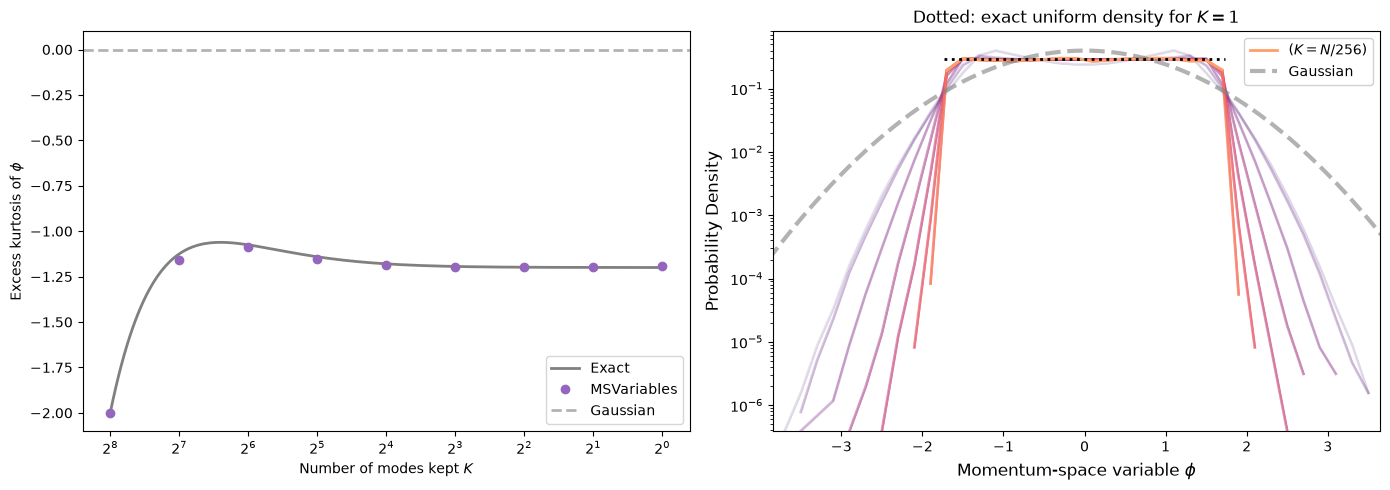

In [9]:
rng = np.random.default_rng(0)
N_model, T_model = 256, 50000
xi = rng.random(T_model)                                  # shared firing probability
model_array = (rng.random((N_model, T_model)) < xi).astype(int)

MS_model = prg.MSVariables(model_array, rg_steps=8)       # K = 256, 128, ..., 1
MS_model_distribution = prg.momentum_space_distribution(MS_model, bins=np.linspace(-4, 4, 41))

r = np.logspace(np.log2(1 / N_model), 0, 200, base=2)
exact_kurtosis = (1/80 + r/20 + r**2/10 - r**3/15 - r**4/30) / (1/12 + r/6)**2 - 3

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(r * N_model, exact_kurtosis, color='0.5', lw=2, label='Exact')
axes[0].plot(MS_model.cutoffs, excess_kurtosis_by_step(MS_model), 'o', color='tab:purple', label='MSVariables')
axes[0].axhline(0, color='0.7', ls='--', lw=2, label='Gaussian')
axes[0].set_xscale('log', base=2)
axes[0].invert_xaxis()
axes[0].set_xlabel('Number of modes kept $K$')
axes[0].set_ylabel('Excess kurtosis of $\\phi$')
axes[0].legend()

prg.plot.plot_momentum_space_distribution(MS_model_distribution, ax=axes[1])
axes[1].hlines(1 / (2 * np.sqrt(3)), -np.sqrt(3), np.sqrt(3), color='k', ls=':', lw=2)
axes[1].set_title('Dotted: exact uniform density for $K = 1$')
plt.tight_layout()
plt.show()

#### The toolbox follows the exact result. Note that this distribution never becomes Gaussian, although nothing in this model is critical: a shared input is enough. That is why the comparison with surrogates and the convergence across steps matter.

### Finally, using it with `run_PRG`

`momentum_space_distribution` can also go in the list of observables of the pipeline, which then handles time windows and subsampling. The bins are set with `momentum_space_bins`.

*Note: with short windows, neurons that stay silent in a window are dropped from it with a warning (silenced here).*

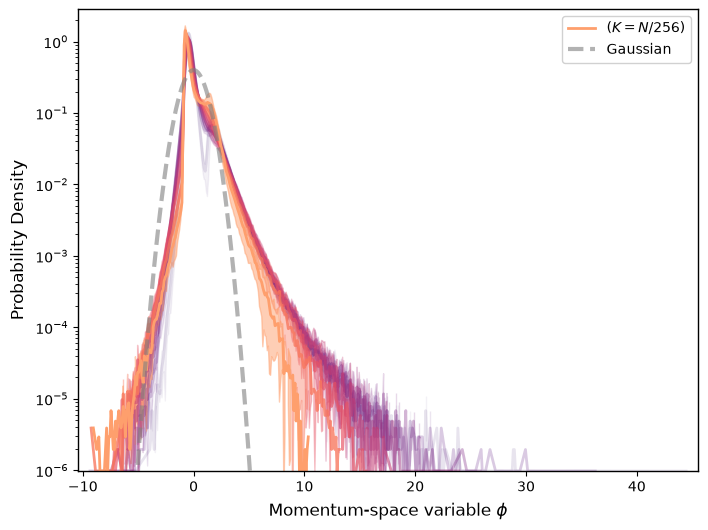

In [10]:
prg_params = prg.config.AnalysisParams()
prg_params.rg_steps = rg_steps
prg_params.observables = [prg.momentum_space_distribution]
prg_params.momentum_space_bins = bins
prg_params.verbose = 'silent'
prg_params.time_slicing.binary_binsize_ms = 5          # bin size of our array
prg_params.time_slicing.window_duration_ms = 12500     # four windows of 2500 bins

results = prg.run_PRG(binary_array, user_params=prg_params)

fig = plt.figure(figsize=(8, 6))
prg.plot.plot_momentum_space_distribution(results['momentum_space_distribution'], style_config=prg_params)
plt.show()

## 🧭 Wrapping up

- `prg.MSVariables(data, rg_steps)` runs the momentum-space coarse graining, and `get_MS_variables(k)` returns the variables built from the $K = N/2^k$ leading modes.
- `prg.momentum_space_distribution(MS_variables, bins=...)` computes their distribution at every step.
- `prg.plot.plot_momentum_space_distribution(...)` plots it against the standard normal, with the same styling options as the other plots.

A non-Gaussian distribution is a sign of collective behavior, but to talk about a fixed point the curves should also stop changing across steps. Always compare with surrogate data.

---
#### References

1. L. Meshulam, J. L. Gauthier, C. D. Brody, D. W. Tank, and W. Bialek, *Coarse graining, fixed points, and scaling in a large population of neurons*, [Phys. Rev. Lett. **123**, 178103 (2019)](https://doi.org/10.1103/PhysRevLett.123.178103).
2. G. Nicoletti, S. Suweis, and A. Maritan, *Scaling and criticality in a phenomenological renormalization group*, [Phys. Rev. Research **2**, 023144 (2020)](https://journals.aps.org/prresearch/abstract/10.1103/PhysRevResearch.2.023144).
3. M. Schmidt, R. Bakker, K. Shen, G. Bezgin, M. Diesmann, and S. J. van Albada, *A multi-scale layer-resolved spiking network model of resting-state dynamics in macaque visual cortical areas*, [PLoS Comput. Biol. **14**, e1006359 (2018)](https://doi.org/10.1371/journal.pcbi.1006359).